# Long-stride trajectories with a universal FlashMD model
### Alanine dipeptide in vacuum, FlashMD at 16 and 64 fs against a 0.5 fs MLIP control

Fatima-Zahrae Akhyar.

Built on the [FlashMD cookbook recipe](https://atomistic-cookbook.org/examples/flashmd/flashmd-demo.html)
and on the mean-force identity used in *Generative modeling of conditional probability distributions on the level-sets
of collective variables* (Akhyar, Zhang, Stoltz, Schütte, [arXiv:2512.17374](https://arxiv.org/abs/2512.17374)).

FlashMD predicts positions and momenta one stride of 16 to 64 fs ahead. The learned map is neither exactly symplectic
nor exactly time-reversible, so nothing guarantees that a thermostatted FlashMD run samples the Boltzmann distribution
$e^{-\beta V}$ of the MLIP it was trained on. The thermostat controls the kinetic temperature, not the distribution of
configurations.

This notebook checks the sampled distribution without a reference run. For a collective variable $\xi$, the free
energy can be estimated from a single trajectory in two ways: from the histogram of $\xi$, and by integrating the mean
force, a conditional average of the MLIP forces on the level sets of $\xi$. The two agree when the frames follow
$e^{-\beta V}$; their difference, level set by level set, is the error of the sampler projected on $\xi$. The test is
applied to the dihedral $\psi$ for FlashMD at 16 and 64 fs. A 0.5 fs MLIP run is used only as a control, to measure
the statistical noise of the test itself.

Running it. `MODE = "full"` reproduces the results (about 1.5 h on a free Colab T4 from scratch, mostly the 0.5 fs
run; *Runtime → Change runtime type → T4 GPU*). Trajectories are saved in chunks and a disconnected session resumes
where it stopped. `MODE = "quick"` runs the whole pipeline in a few minutes on very short trajectories: it checks
that the code runs, but its numbers are not converged and must not be interpreted.

In [4]:
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "flashmd>=0.3.0,<0.4", "chemiscope>=1.1,<2"],
                   check=True)

In [5]:
import warnings
warnings.filterwarnings("ignore")
import io, os, time
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import ase, ase.io, ase.units as units
from ase.constraints import FixCom
from ase.md.langevin import Langevin as AseLangevin
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution, Stationary, ZeroRotation
from ase.optimize import BFGS
from IPython.display import Markdown, display

MODE = "full"          # "full": results of the study, "quick": pipeline check
QUICK = MODE == "quick"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
T_K, TAU_FS, SEED = 400.0, 100.0, 1234
MODEL_NAME = "pet-omatpes-v2"
kT = units.kB * T_K
EV2KJ = 96.485

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    WORKDIR = "/content/drive/MyDrive/flashmd_levelsets"
else:
    WORKDIR = os.path.join("tmp", "flashmd_levelsets")
os.makedirs(WORKDIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print(f"{DEVICE} | torch {torch.__version__} | ase {ase.__version__} | mode {MODE} | {WORKDIR}")

Mounted at /content/drive
cuda | torch 2.14.1+cu130 | ase 3.29.0 | mode full | /content/drive/MyDrive/flashmd_levelsets


## 1. The mean-force identity as a test of a sampler

Let $\xi$ be a collective variable, $\mu(dx)\propto e^{-\beta V(x)}dx$, and $\mu_z$ the conditional distribution on
the level set $\Sigma_z=\{\xi=z\}$. The free energy $F(z)=-\beta^{-1}\ln\int e^{-\beta V}\delta(\xi(x)-z)\,dx$
satisfies (den Otter 2000; Ciccotti, Kapral and Vanden-Eijnden 2005; Lelièvre, Rousset and Stoltz 2010; Eq. (21) of
the paper above with $k=1$)

$$
F'(z)=\mathbb E_{\mu_z}[f],\qquad f=\nabla V\cdot G-\beta^{-1}\nabla\cdot G,\qquad G=\frac{\nabla\xi}{|\nabla\xi|^2}.
$$

Now let $\hat\mu$ be the stationary distribution of positions actually sampled by an integrator, and define $\hat V$ by
$\hat\mu\propto e^{-\beta\hat V}$ (any positive density can be written this way). The same integration by parts on each
level set, applied to $\hat\mu$, gives

$$
\hat F'(z)-\mathbb E_{\hat\mu_z}[f]=\mathbb E_{\hat\mu_z}\big[(\nabla\hat V-\nabla V)\cdot G\big],
$$

where $\hat F=-\beta^{-1}\ln\hat p$ is the free energy computed from the histogram $\hat p$ of $\xi$ along the
trajectory. Both terms on the left come from the trajectory alone: the histogram, and the bin averages of $f$ evaluated
with the MLIP forces stored on every frame ($G$ and $\nabla\cdot G$ come from `torch.autograd`). The left-hand side
vanishes for an exact sampler of the MLIP. When it does not, it is the error of the integrator's effective force,
projected on $\xi$, level set by level set.

With a finite run the difference never vanishes exactly: the histogram needs converged populations along $\xi$, while
the mean force only needs equilibrium within each level set. The 0.5 fs MLIP run measures this noise floor. The FlashMD
runs are longer than the control, so using its noise floor is conservative. The test is applied to $\xi=\psi$: the
unbiased runs go back and forth along $\psi$ many times (counted below), whereas they visit the $\phi>0$ region
too rarely for a histogram in $\phi$ to converge.

In [6]:
from flashmd import get_pretrained
from flashmd.ase import EnergyCalculator
from flashmd.ase.langevin import Langevin as FlashLangevin
mlip_model, flashmd_16 = get_pretrained(MODEL_NAME, 16)
_, flashmd_64 = get_pretrained(MODEL_NAME, 64)
FLASHMD_MODELS = {16: flashmd_16, 64: flashmd_64}

def make_mlip_calc():
    return EnergyCalculator(mlip_model, device=DEVICE)

In [7]:
# Alanine dipeptide (ACE-ALA-NME), 22 atoms
ALA2_XYZ = """22

C 0.97411 1.93024 3.05538
H 0.36282 2.75592 3.57332
H 1.51432 1.33232 3.74716
H 1.67973 2.47151 2.41879
C -0.03799 1.07461 2.30473
O -1.08369 0.59640 2.92038
N 0.23757 1.11882 0.97817
H 1.15274 1.35749 0.67311
C -0.39014 0.19490 0.03610
H -0.98709 -0.49847 0.74973
C -1.26848 1.14242 -0.79791
H -0.78686 2.11604 -0.89797
H -1.46077 0.68288 -1.86875
H -2.23101 1.22072 -0.35221
C 0.77823 -0.56996 -0.77326
O 1.89554 -0.67652 -0.18400
N 0.36865 -1.14568 -1.89879
H -0.55894 -1.47715 -2.13769
C 1.32540 -1.74846 -2.77107
H 2.23101 -1.16063 -2.69165
H 1.57851 -2.75592 -2.42020
H 0.97968 -1.72187 -3.74716
"""
PHI = [4, 6, 8, 14]     # C(=O)-N-CA-C
PSI = [6, 8, 14, 16]    # N-CA-C-N
BONDS = [(0, 4), (4, 5), (4, 6), (6, 8), (8, 10), (8, 14), (14, 15), (14, 16), (16, 18),
         (0, 1), (0, 2), (0, 3), (6, 7), (8, 9), (10, 11), (10, 12), (10, 13), (16, 17),
         (18, 19), (18, 20), (18, 21)]
BOX = 30.0   # large periodic box

def fresh_atoms(positions=None):
    a = ase.io.read(io.StringIO(ALA2_XYZ), format="xyz")
    if positions is not None:
        a.positions = positions
    a.cell = [BOX] * 3
    a.pbc = True
    return a

def dihedral_t(x):
    # x: (..., 4, 3) --> dihedral in (-pi, pi]
    b0 = x[..., 0, :] - x[..., 1, :]
    b1 = x[..., 2, :] - x[..., 1, :]
    b2 = x[..., 3, :] - x[..., 2, :]
    b1n = b1 / b1.norm(dim=-1, keepdim=True)
    v = b0 - (b0 * b1n).sum(-1, keepdim=True) * b1n
    w = b2 - (b2 * b1n).sum(-1, keepdim=True) * b1n
    return torch.atan2((torch.cross(b1n, v, dim=-1) * w).sum(-1), (v * w).sum(-1))

def dihedral_np(pos, idx):
    with torch.no_grad():
        return dihedral_t(torch.as_tensor(np.asarray(pos)[..., idx, :], dtype=torch.float64)).numpy()

def cv_terms(pos, idx):
    # z, G = grad xi / |grad xi|^2 and div G, on the 4 atomsof the dihedral (those are the only ones xi depends on)
    pos = np.asarray(pos, dtype=np.float64)
    x = torch.as_tensor(pos[:, idx, :]).clone().requires_grad_(True)
    z = dihedral_t(x)
    g, = torch.autograd.grad(z.sum(), x, create_graph=True)
    G = g / (g ** 2).sum(dim=(-1, -2))[:, None, None]
    div = torch.zeros(len(pos), dtype=torch.float64)
    Gf = G.reshape(len(pos), 12)
    for k in range(12):
        h, = torch.autograd.grad(Gf[:, k].sum(), x, retain_graph=True)
        div += h.reshape(len(pos), 12)[:, k]
    return z.detach().numpy(), G.detach().numpy(), div.detach().numpy()

def local_mean_force(pos, forces, idx, batch=4096):
    # z and f = grad V . G - kT div G on every frame (grad V = -forces), in eV/rad
    zs, fs = [], []
    for s in range(0, len(pos), batch):
        z, G, div = cv_terms(pos[s:s + batch], idx)
        fs.append(-(np.asarray(forces[s:s + batch], dtype=np.float64)[:, idx, :] * G).sum(axis=(1, 2)) - kT * div)
        zs.append(z)
    return np.concatenate(zs), np.concatenate(fs)

# Sanity check of the autograd divergence against central finite differences on a random geometry
_rng = np.random.default_rng(0)
_x = fresh_atoms().positions + 0.1 * _rng.standard_normal((22, 3))
_, _, _div = cv_terms(_x[None], PSI)
_eps, _fd = 1e-5, 0.0
for a in PSI:
    for c in range(3):
        xp, xm = _x.copy(), _x.copy(); xp[a, c] += _eps; xm[a, c] -= _eps
        _fd += (cv_terms(xp[None], PSI)[1][0, PSI.index(a), c] - cv_terms(xm[None], PSI)[1][0, PSI.index(a), c]) / (2 * _eps)
print(f"div G: autograd {_div[0]:.6f}, finite differences {_fd:.6f}")
assert abs(_div[0] - _fd) < 1e-5 * max(1.0, abs(_fd))
atoms0 = fresh_atoms(); atoms0.center()
atoms0.calc = make_mlip_calc()
BFGS(atoms0, logfile=None).run(fmax=0.02, steps=300)
X0 = atoms0.positions.copy()
print("relaxed structure: phi = %.1f, psi = %.1f deg" % tuple(np.degrees(dihedral_np(X0, i)) for i in (PHI, PSI)))

div G: autograd -0.261062, finite differences -0.261062
relaxed structure: phi = -161.9, psi = 167.7 deg


## 2. Simulations

All runs use PET-OMATPES-v2 as the MLIP and a Langevin thermostat at 400 K with a 100 fs time constant, starting from
the relaxed structure with Maxwell-Boltzmann momenta.

| run | integrator | length (full mode) |
|---|---|---|
| ref_mlip_0.5fs | the MLIP with ASE's Langevin integrator, 0.5 fs | 40 ps |
| flashmd_16fs | flashmd.ase.langevin.Langevin, 16 fs rescale_energy=True, random_rotation=True (cookbook settings) | 96 ps |
| flashmd_64fs | the same with the 64 fs model | 192 ps or until a bond breaks |

Positions, momenta, MLIP forces and MLIP energies are stored every 10 fs for the control run and at every stride for
FlashMD. The MLIP forces on FlashMD frames are not used to propagate anything, they are only needed for the mean force.

In [8]:
SUFFIX = "_quick" if QUICK else ""
RUNS = {
    "ref_mlip_0.5fs": dict(kind="mlip",    dt_fs=0.5, n_steps=6_000 if QUICK else 80_000, save_every=20),
    "flashmd_16fs":   dict(kind="flashmd", dt_fs=16,  n_steps=300 if QUICK else 6_000,    save_every=1),
    "flashmd_64fs":   dict(kind="flashmd", dt_fs=64,  n_steps=150 if QUICK else 3_000,    save_every=1),
}
META = dict(model=MODEL_NAME, T_K=T_K, tau_fs=TAU_FS, seed=SEED)

def make_dynamics(cfg, atoms, rng):
    dt = cfg["dt_fs"] * units.fs
    if cfg["kind"] == "mlip":
        atoms.set_constraint(FixCom())
        return AseLangevin(atoms, dt, temperature_K=T_K, friction=1.0 / (TAU_FS * units.fs), fixcm=False, rng=rng)
    return FlashLangevin(atoms, dt, T_K, FLASHMD_MODELS[cfg["dt_fs"]], time_constant=TAU_FS * units.fs,
                         fixcm=True, device=DEVICE, rescale_energy=True, random_rotation=True, rng=rng)
def broken(pos, tol=2.2):
    i, j = np.array(BONDS).T
    return np.linalg.norm(pos[i] - pos[j], axis=-1).max() > tol


def check_file(name, cfg, d):
    for key in ("dt_fs", "save_every"):
        if float(d[key]) != float(cfg[key]):
            raise ValueError(f"{name}: {key} on disk = {d[key]}, expected {cfg[key]}; delete or rename the file")
    for key, val in META.items():
        if key in d.files and str(d[key]) != str(val):
            raise ValueError(f"{name}: {key} on disk = {d[key]}, expected {val}; delete or rename the file")
    if int(d["n_done"]) > cfg["n_steps"]:
        raise ValueError(f"{name}: {int(d['n_done'])} steps on disk, more than the {cfg['n_steps']} requested")

def run_md(name, cfg, chunk=500):
    # save positions, mommenta, forces and potential energy  (resumes from the last saved chunk)
    path = os.path.join(WORKDIR, name + SUFFIX + ".npz")
    store = dict(pos=[], mom=[], frc=[], epot=[])
    n_done, wall, status = 0, 0.0, "ok"
    if os.path.exists(path):
        d = np.load(path)
        check_file(name, cfg, d)
        n_done, wall, status = int(d["n_done"]), float(d["wall"]), str(d["status"])
        for k in store:
            store[k] = list(d[k])
        if n_done >= cfg["n_steps"] or status != "ok":
            print(f"[{name}] on disk: {n_done} steps, status: {status}")
            return
    rng = np.random.default_rng([SEED, sum(map(ord, name)), n_done])
    atoms = fresh_atoms(store["pos"][-1] if store["pos"] else X0)
    atoms.calc = make_mlip_calc()
    if store["mom"]:
        atoms.set_momenta(store["mom"][-1])
    else:
        MaxwellBoltzmannDistribution(atoms, temperature_K=T_K, rng=rng)
        Stationary(atoms); ZeroRotation(atoms)
    dyn = make_dynamics(cfg, atoms, rng)

    def save():
        arrays = {k: np.array(v, dtype=np.float64 if k == "epot" else np.float32) for k, v in store.items()}
        np.savez(path, **arrays, n_done=n_done, wall=wall, status=status, dt_fs=cfg["dt_fs"],
                 save_every=cfg["save_every"], **META)

    t0 = time.time()
    while n_done < cfg["n_steps"]:
        try:
            for _ in range(cfg["save_every"]):
                dyn.step()
            n_done += cfg["save_every"]
        except Exception as e:
            status = f"crashed: {type(e).__name__}"
            break
        pos = atoms.positions.copy()
        if not np.isfinite(pos).all() or not np.isfinite(atoms.get_momenta()).all() or broken(pos):
            status = "broken bond"
            break
        store["pos"].append(pos); store["mom"].append(atoms.get_momenta())
        store["frc"].append(atoms.get_forces(apply_constraint=False)); store["epot"].append(atoms.get_potential_energy())
        if len(store["pos"]) % chunk == 0:
            wall += time.time() - t0; t0 = time.time(); save()
            if len(store["pos"]) % (4 * chunk) == 0:
                print(f"[{name}] {n_done * cfg['dt_fs'] / 1000:6.1f} ps / {cfg['n_steps'] * cfg['dt_fs'] / 1000:.0f} ps"
                      f" ({wall / 60:.1f} min)")
    wall += time.time() - t0
    save()
    print(f"[{name}] done: {n_done * cfg['dt_fs'] / 1000:.1f} ps, status: {status}, {wall / 60:.1f} min")

In [9]:
for name, cfg in RUNS.items():
    run_md(name, cfg)

[ref_mlip_0.5fs] on disk: 80000 steps, status: ok
[flashmd_16fs] on disk: 6000 steps, status: ok
[flashmd_64fs] on disk: 1271 steps, status: broken bond


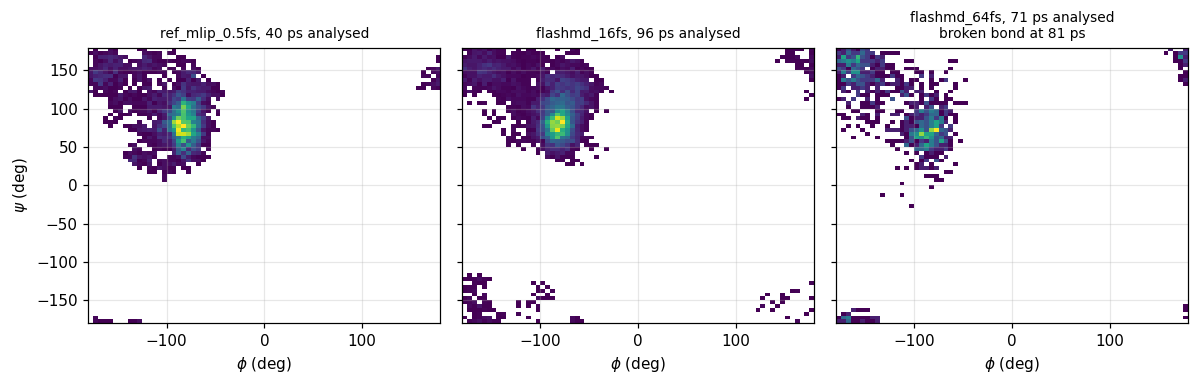

In [10]:
def load(name):
    d = np.load(os.path.join(WORKDIR, name + SUFFIX + ".npz"))
    out = {k: d[k] for k in ("pos", "mom", "frc", "epot")}
    for k in ("pos", "mom", "frc"):
        out[k] = out[k].astype(np.float64)
    out["status"], out["wall"] = str(d["status"]), float(d["wall"])
    out["t_ps"] = np.arange(1, len(out["pos"]) + 1) * float(d["save_every"]) * float(d["dt_fs"]) / 1000
    out["phi"], out["psi"] = dihedral_np(out["pos"], PHI), dihedral_np(out["pos"], PSI)
    return out

def select(d, keep):
    n = len(keep)
    return {k: (v[keep] if isinstance(v, np.ndarray) and v.ndim and len(v) == n else v) for k, v in d.items()}

NAMES = list(RUNS)
RAW = {name: load(name) for name in NAMES}
DATA = dict(RAW)
# if the 64 fs run broke, drop its last 10 ps so that the analysis is not driven by the frames leading to the break
if RAW["flashmd_64fs"]["status"] != "ok":
    t = RAW["flashmd_64fs"]["t_ps"]
    DATA["flashmd_64fs"] = select(RAW["flashmd_64fs"], t < t[-1] - 10)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for ax, name in zip(axes, NAMES):
    d = DATA[name]
    ax.hist2d(np.degrees(d["phi"]), np.degrees(d["psi"]), bins=72, range=[[-180, 180]] * 2, cmap="viridis", cmin=1)
    note = "" if RAW[name]["status"] == "ok" else f"\n{RAW[name]['status']} at {RAW[name]['t_ps'][-1]:.0f} ps"
    ax.set(title=f"{name}, {d['t_ps'][-1]:.0f} ps analysed{note}", xlabel=r"$\phi$ (deg)", xlim=(-180, 180), ylim=(-180, 180))
    ax.title.set_fontsize(9)
axes[0].set_ylabel(r"$\psi$ (deg)")
plt.tight_layout(); plt.show()

## 3. The mean-force test on $\psi$

For each run: $F_{\rm mf}$ and $F_{\rm hist}$ on the 10° bins of $\psi$ visited at least 40 times (the longest
contiguous arc of such bins), and the count-weighted RMS difference between them, the gap. $F_{\rm hist}$ is
shifted to minimise the gap, so a constant offset does not count. Error bars come from a block bootstrap the run is cut
into 10 blocks of consecutive frames, resampled with replacement. The table below gives the block length and the number
of transitions of $\psi$ between its two most populated regions so that one can check that each block contains several
of them.

The second row of the figure resolves the gap level set by level set, the finite-difference slope of $F_{\rm hist}$
between neighbouring bins minus the mean force at their midpoint, an estimate of
$\mathbb E_{\hat\mu_z}[(\nabla\hat V-\nabla V)\cdot G]$.

,length (ps),frames,block length (ps),psi transitions,transitions per block,psi bins tested,bootstrap samples kept
ref_mlip_0.5fs,40.0,4000.0,4.0,11.0,1.1,15.0,262.0
flashmd_16fs,96.0,6000.0,9.6,34.0,3.4,15.0,298.0
flashmd_64fs,71.2,1113.0,7.1,11.0,1.1,13.0,300.0


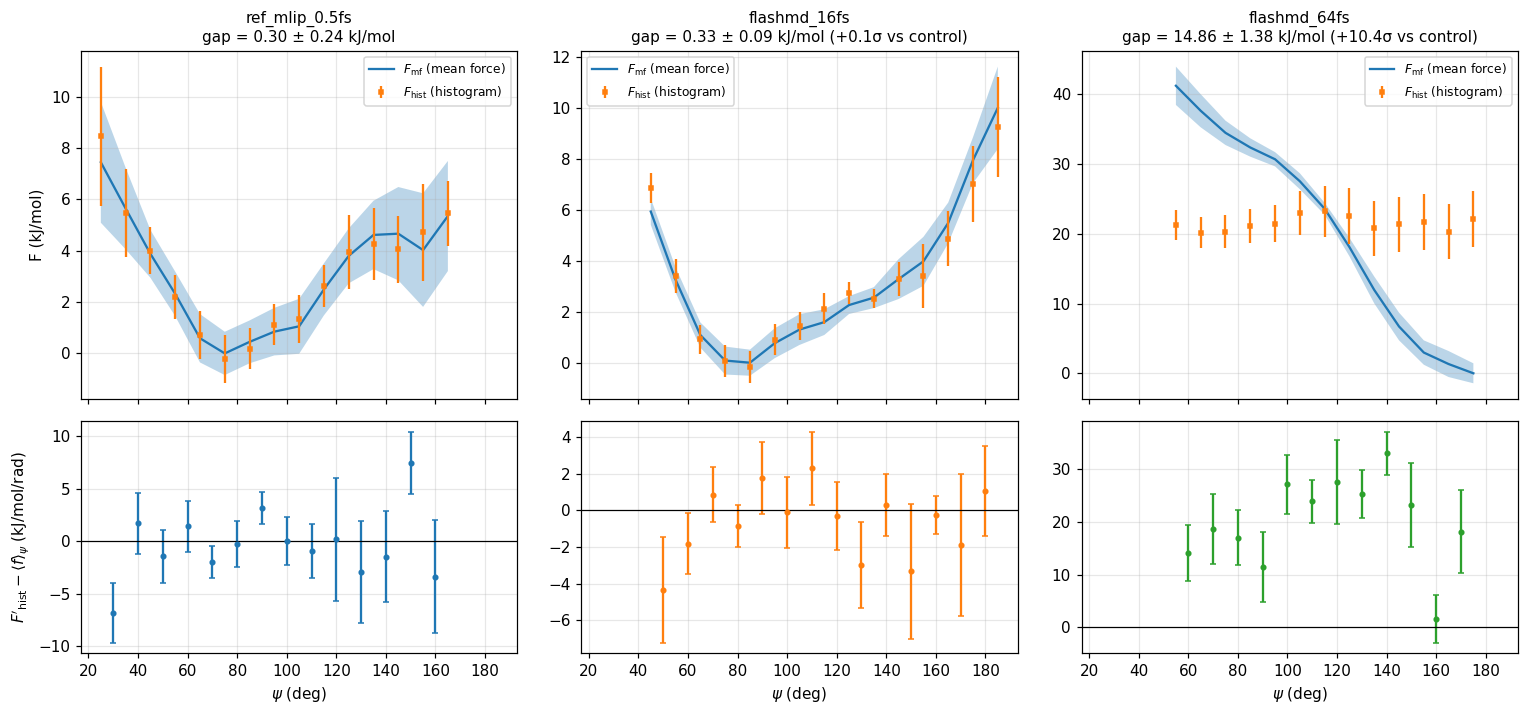

In [11]:
NB, NBLOCK = 36, 10
MINC, NBOOT = (3, 100) if QUICK else (40, 300)
EDGES = np.linspace(-np.pi, np.pi, NB + 1); CENT = 0.5 * (EDGES[1:] + EDGES[:-1]); H = EDGES[1] - EDGES[0]
def largest_arc(ok):
    if ok.all():
        return np.arange(NB)
    order = (np.arange(NB) + np.argmin(ok)) % NB
    best, cur = [], []
    for i in order:
        cur = cur + [i] if ok[i] else []
        if len(cur) > len(best):
            best = cur
    return np.array(best, dtype=int)

def binned(z, f, w):
    b = np.clip(np.digitize(z, EDGES) - 1, 0, NB - 1)
    cnt = np.bincount(b, weights=w, minlength=NB)
    return cnt, np.bincount(b, weights=w * f, minlength=NB) / np.maximum(cnt, 1e-300)

def test_on_arc(z, f, arc, w):
    cnt, mf = binned(z, f, w)
    c, m = cnt[arc], mf[arc]
    if (c == 0).any():
        return None
    Fm = np.concatenate([[0], np.cumsum(0.5 * (m[1:] + m[:-1]) * H)])
    Fh = -kT * np.log(c / c.sum())
    Fh = Fh - np.average(Fh - Fm, weights=c)
    gap = np.sqrt(np.average((Fh - Fm) ** 2, weights=c))
    local = -kT * np.log(c[1:] / c[:-1]) / H - 0.5 * (m[1:] + m[:-1])
    return Fm - Fm.mean(), Fh - Fm.mean(), gap, local, local.mean()

def transitions(psi):
    # number of transitions between psi in [40, 90] deg and psi in [140, 190] deg
    p = np.degrees(psi) % 360
    state = np.where((p > 40) & (p < 90), 0, np.where((p > 140) & (p < 190), 1, -1))
    s = state[state >= 0]
    return int((s[1:] != s[:-1]).sum())

def mean_force_test(d, idx=PSI):
    z, f = local_mean_force(d["pos"], d["frc"], idx)
    arc = largest_arc(binned(z, f, np.ones(len(z)))[0] >= MINC)
    if len(arc) < 3:
        raise RuntimeError("fewer than 3 contiguous psi bins with enough samples: run longer")
    Fm, Fh, gap, local, offset = test_on_arc(z, f, arc, np.ones(len(z)))
    blk = np.arange(len(z)) * NBLOCK // len(z)
    rng, boot = np.random.default_rng(0), []
    for _ in range(NBOOT):
        w = np.bincount(rng.integers(NBLOCK, size=NBLOCK), minlength=NBLOCK)[blk].astype(float)
        r = test_on_arc(z, f, arc, w)
        if r is not None:
            boot.append(r)
    sd = [np.std(np.array(v), axis=0) for v in zip(*boot)]
    return dict(arc=arc, Fm=Fm, Fh=Fh, gap=gap, local=local, offset=offset, Fm_se=sd[0], Fh_se=sd[1], gap_se=sd[2],
                local_se=sd[3], offset_se=sd[4], n_boot=len(boot))

RES = {name: mean_force_test(DATA[name]) for name in NAMES}
ref = RES["ref_mlip_0.5fs"]
for name in NAMES:
    r = RES[name]
    r["excess"] = r["gap"] - ref["gap"]
    r["excess_se"] = 0.0 if name == "ref_mlip_0.5fs" else np.hypot(r["gap_se"], ref["gap_se"])
    r["z_vs_ref"] = r["excess"] / r["excess_se"] if r["excess_se"] > 0 else 0.0

SAMPLING = pd.DataFrame({name: {
    "length (ps)": DATA[name]["t_ps"][-1],
    "frames": len(DATA[name]["pos"]),
    "block length (ps)": DATA[name]["t_ps"][-1] / NBLOCK,
    "psi transitions": transitions(DATA[name]["psi"]),
    "transitions per block": transitions(DATA[name]["psi"]) / NBLOCK,
    "psi bins tested": len(RES[name]["arc"]),
    "bootstrap samples kept": RES[name]["n_boot"]} for name in NAMES}).T
display(SAMPLING.round(1))

fig, axes = plt.subplots(2, 3, figsize=(14, 6.6), sharex=True, gridspec_kw=dict(height_ratios=[3, 2]))
for j, name in enumerate(NAMES):
    r = RES[name]
    x = np.unwrap(np.degrees(CENT[r["arc"]]), period=360)
    m = r["Fm"].min()
    ax = axes[0, j]
    ax.fill_between(x, (r["Fm"] - m - r["Fm_se"]) * EV2KJ, (r["Fm"] - m + r["Fm_se"]) * EV2KJ, alpha=0.3)
    ax.plot(x, (r["Fm"] - m) * EV2KJ, "-", label=r"$F_{\rm mf}$ (mean force)")
    ax.errorbar(x, (r["Fh"] - m) * EV2KJ, r["Fh_se"] * EV2KJ, fmt="s", ms=3, label=r"$F_{\rm hist}$ (histogram)")
    zs = "" if name == "ref_mlip_0.5fs" else f" ({r['z_vs_ref']:+.1f}σ vs control)"
    ax.set_title(f"{name}\ngap = {r['gap'] * EV2KJ:.2f} ± {r['gap_se'] * EV2KJ:.2f} kJ/mol{zs}", fontsize=10)
    ax.legend(fontsize=8)
    xm = 0.5 * (x[1:] + x[:-1])
    axes[1, j].errorbar(xm, r["local"] * EV2KJ, r["local_se"] * EV2KJ, fmt="o", ms=3, capsize=2, color=f"C{j}")
    axes[1, j].axhline(0, color="k", lw=0.8)
    axes[1, j].set_xlabel(r"$\psi$ (deg)")
axes[0, 0].set_ylabel("F (kJ/mol)")
axes[1, 0].set_ylabel(r"$F'_{\rm hist}-\langle f\rangle_\psi$ (kJ/mol/rad)")
plt.tight_layout(); plt.show()

### Independent checks

The test relies on the stored MLIP forces, so they are first recomputed with a fresh calculator on a few frames of each
FlashMD run. Then come checks that do not use the forces at all; equipartition per element, the mean and distribution
of the MLIP potential energy and whether the run broke a bond. Uncertainties are standard errors over the same 10 blocks.

max |F_stored - F_recomputed| (eV/Å)
  flashmd_16fs   2.3e-06
  flashmd_64fs   1.7e-06


,T_H (K),T_C (K),T_N (K),T_O (K),<V> - <V_control> (kJ/mol),status
ref_mlip_0.5fs,397 ± 5,409 ± 4,408 ± 6,397 ± 7,+0.0 ± 0.0,ok
flashmd_16fs,404 ± 2,402 ± 3,398 ± 3,396 ± 4,+4.7 ± 1.6,ok
flashmd_64fs,412 ± 4,389 ± 5,390 ± 9,382 ± 10,+25.0 ± 2.3,broken bond at 81 ps


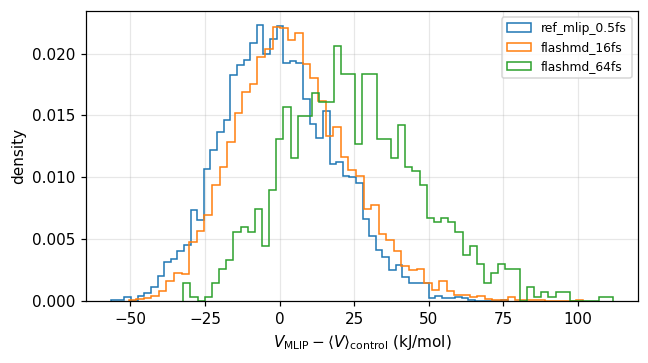

In [12]:
print("max |F_stored - F_recomputed| (eV/Å)")
for name in ["flashmd_16fs", "flashmd_64fs"]:
    d = DATA[name]
    errs = []
    for i in np.linspace(0, len(d["pos"]) - 1, 5).astype(int):
        a = fresh_atoms(d["pos"][i]); a.calc = make_mlip_calc()
        errs.append(np.abs(a.get_forces() - d["frc"][i]).max())
    print(f"  {name:14s} {max(errs):.1e}")

masses = fresh_atoms().get_masses(); symbols = np.array(fresh_atoms().get_chemical_symbols())
ELEMENTS = ["H", "C", "N", "O"]
# mean over blocks and standard error of the mean, x: (frames, ...)
def block_stats(x):
    blocks = np.array([b.mean(0) for b in np.array_split(x, NBLOCK)])
    return blocks.mean(0), blocks.std(0, ddof=1) / np.sqrt(NBLOCK)

DIAG = {}
for name in NAMES:
    d = DATA[name]
    ke = 0.5 * (d["mom"] ** 2).sum(-1) / masses
    T_el = np.stack([(2 * ke / (3 * units.kB) / (1 - masses / masses.sum()))[:, symbols == el].mean(1)
                     for el in ELEMENTS], 1)
    T_m, T_se = block_stats(T_el)
    V_m, V_se = block_stats(d["epot"])
    DIAG[name] = dict(T=T_m, T_se=T_se, V=V_m, V_se=V_se)
for name in NAMES:
    DIAG[name]["dV"] = (DIAG[name]["V"] - DIAG["ref_mlip_0.5fs"]["V"]) * EV2KJ
    DIAG[name]["dV_se"] = 0.0 if name == "ref_mlip_0.5fs" else np.hypot(DIAG[name]["V_se"], DIAG["ref_mlip_0.5fs"]["V_se"]) * EV2KJ

table = {}
for name in NAMES:
    D = DIAG[name]
    row = {f"T_{el} (K)": f"{D['T'][k]:.0f} ± {D['T_se'][k]:.0f}" for k, el in enumerate(ELEMENTS)}
    row["<V> - <V_control> (kJ/mol)"] = f"{D['dV']:+.1f} ± {D['dV_se']:.1f}"
    row["status"] = RAW[name]["status"] + ("" if RAW[name]["status"] == "ok" else f" at {RAW[name]['t_ps'][-1]:.0f} ps")
    table[name] = row
display(pd.DataFrame(table).T)

fig, ax = plt.subplots(figsize=(6, 3.4))
V0 = DIAG["ref_mlip_0.5fs"]["V"]
for name in NAMES:
    ax.hist((DATA[name]["epot"] - V0) * EV2KJ, bins=60, density=True, histtype="step", lw=1.5, label=name)
ax.set(xlabel=r"$V_{\rm MLIP}-\langle V\rangle_{\rm control}$ (kJ/mol)", ylabel="density"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 4. Summary


In [13]:
kj = lambda x: x * EV2KJ
r0 = RES["ref_mlip_0.5fs"]

def gap_sentence(name):
    r = RES[name]
    s = f"{kj(r['gap']):.2f} ± {kj(r['gap_se']):.2f} kJ/mol"
    if r["z_vs_ref"] < 2:
        bound = kj(r["excess"] + 2 * r["excess_se"])
        return (s + f", no excess over the control ({r['z_vs_ref']:+.1f}σ). At this run length, an excess gap larger "
                f"than about {max(bound, 0):.1f} kJ/mol would have been detected at 2σ")
    return s + f", an excess of {kj(r['excess']):.1f} ± {kj(r['excess_se']):.1f} kJ/mol over the control ({r['z_vs_ref']:.1f}σ)"

def dv_sentence(name):
    D = DIAG[name]
    z = D["dV"] / D["dV_se"]
    verdict = "significant" if abs(z) >= 3 else ("marginal" if abs(z) >= 2 else "not significant")
    return f"{D['dV']:+.1f} ± {D['dV_se']:.1f} kJ/mol ({z:+.1f}σ, {verdict})"

def temps(name):
    D = DIAG[name]
    return ", ".join(f"{el} {D['T'][k]:.0f} ± {D['T_se'][k]:.0f} K" for k, el in enumerate(ELEMENTS))

r64 = RES["flashmd_64fs"]
lines = []
if QUICK:
    lines.append("> **Quick mode: the trajectories are far too short for these numbers to mean anything. "
                 "Set `MODE = \"full\"` to obtain the results of the study.**\n")
lines.append(f"""
**Noise floor.** For the 0.5 fs MLIP control ({DATA['ref_mlip_0.5fs']['t_ps'][-1]:.0f} ps), the gap between the
histogram and mean-force estimates of $F(\\psi)$ is {kj(r0['gap']):.2f} ± {kj(r0['gap_se']):.2f} kJ/mol.

**FlashMD 16 fs** ({DATA['flashmd_16fs']['t_ps'][-1]:.0f} ps): gap {gap_sentence('flashmd_16fs')}.
Mean MLIP energy relative to the control: {dv_sentence('flashmd_16fs')}. Per-element temperatures: {temps('flashmd_16fs')}.

**FlashMD 64 fs** ({DATA['flashmd_64fs']['t_ps'][-1]:.0f} ps analysed, status: {RAW['flashmd_64fs']['status']}): gap
{gap_sentence('flashmd_64fs')}. Averaged over the {len(r64['arc']) - 1} tested level sets, the local difference
$F'_{{\\rm hist}}-\\langle f\\rangle_\\psi$ is {kj(r64['offset']):+.1f} ± {kj(r64['offset_se']):.1f} kJ/mol/rad
(control: {kj(r0['offset']):+.1f} ± {kj(r0['offset_se']):.1f}). Mean MLIP energy relative to the control:
{dv_sentence('flashmd_64fs')}. Per-element temperatures: {temps('flashmd_64fs')}.

For reference, the control gives: {temps('ref_mlip_0.5fs')}, with the thermostat at {T_K:.0f} K.
""")
display(Markdown("\n".join(lines)))


**Noise floor.** For the 0.5 fs MLIP control (40 ps), the gap between the
histogram and mean-force estimates of $F(\psi)$ is 0.30 ± 0.24 kJ/mol.

**FlashMD 16 fs** (96 ps): gap 0.33 ± 0.09 kJ/mol, no excess over the control (+0.1σ). At this run length, an excess gap larger than about 0.5 kJ/mol would have been detected at 2σ.
Mean MLIP energy relative to the control: +4.7 ± 1.6 kJ/mol (+3.0σ, significant). Per-element temperatures: H 404 ± 2 K, C 402 ± 3 K, N 398 ± 3 K, O 396 ± 4 K.

**FlashMD 64 fs** (71 ps analysed, status: broken bond): gap
14.86 ± 1.38 kJ/mol, an excess of 14.6 ± 1.4 kJ/mol over the control (10.4σ). Averaged over the 12 tested level sets, the local difference
$F'_{\rm hist}-\langle f\rangle_\psi$ is +20.1 ± 1.7 kJ/mol/rad
(control: -0.4 ± 0.9). Mean MLIP energy relative to the control:
+25.0 ± 2.3 kJ/mol (+10.7σ, significant). Per-element temperatures: H 412 ± 4 K, C 389 ± 5 K, N 390 ± 9 K, O 382 ± 10 K.

For reference, the control gives: H 397 ± 5 K, C 409 ± 4 K, N 408 ± 6 K, O 397 ± 7 K, with the thermostat at 400 K.


### Scope and limitations

- The test sees errors of the sampled distribution that change the free energy along $\psi$. Errors in directions that
  leave $F(\psi)$ unchanged are invisible to it, which is why the energy and temperature checks are reported alongside;
  errors in the dynamics (rates, correlation times) are not tested at all.
- A gap compatible with the control is a statement at the resolution set by the run length, quoted in the summary, not
  a proof of exact sampling.
- Extending the test to $\xi=(\phi,\psi)$ ($k=2$ in Eq. (21)) needs runs long enough to converge the populations of
  $\phi$, or a biased run along $\phi$.
- One molecule, in vacuum, at one temperature, with one pretrained model. The same code applies unchanged to the
  solvated alanine dipeptide of the FlashMD recipe, at a higher cost.
- `flashmd` 0.3 also ships symplectic models for `pet-omatpes` (v1); comparing symplectic and non-symplectic models
  with this test is a natural next step.

In [16]:
import chemiscope
d = DATA["flashmd_64fs"]; sel = np.linspace(0, len(d["pos"]) - 1, min(400, len(d["pos"]))).astype(int)
names = list(fresh_atoms().get_chemical_symbols())
structures = [{"size": len(names), "names": names,
               "x": d["pos"][i][:, 0].tolist(), "y": d["pos"][i][:, 1].tolist(), "z": d["pos"][i][:, 2].tolist()}
              for i in sel]
chemiscope.write_input("flashmd_64fs.json.gz", structures=structures,
                       properties={"phi": np.degrees(d["phi"][sel]), "psi": np.degrees(d["psi"][sel]),
                                   "time_ps": d["t_ps"][sel], "V_kJmol": (d["epot"][sel] - V0) * EV2KJ},
                       settings=chemiscope.quick_settings(x="phi", y="psi", map_color="V_kJmol", trajectory=True))
from google.colab import files
files.download("flashmd_64fs.json.gz")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>